# Reducción, auditoría y ablación

En este último notebook hacemos tres comprobaciones para cerrar el análisis, si PCA o UMAP mejoran a los dos mejores modelos, si la política por grupos es consistente, y cuánto dependen la SVM y el HGB de Tenure y DaySinceLastOrder. Contrastamos las tres con la CV agrupada y con la evaluación en test, para decidir si vale la pena cambiar el pipeline final.

c:\Users\ASUS\Desktop\V8-final\.venv\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
c:\Users\ASUS\Desktop\V8-final\.venv\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_la

,Modelo,Variante,Dimensiones,% reducción,PR-AUC train,PR-AUC val,PR-AUC val std,Brecha,ROC-AUC val,PR-AUC test,t_fit_s
0,HistGradientBoosting,Sin reducción,37,0.0000,1.0000,0.8736,0.0145,0.1264,0.9588,0.9228,2.3516
1,HistGradientBoosting,PCA-23 (presupuesto fijo),23,37.8378,1.0000,0.8266,0.0231,0.1734,0.9457,0.8700,3.6764
2,HistGradientBoosting,PCA-10,10,72.9730,1.0000,0.6930,0.0242,0.3070,0.8830,0.6292,1.3234
3,HistGradientBoosting,UMAP-10,10,72.9730,1.0000,0.5748,0.0427,0.4252,0.8355,0.6450,3.9894
4,HistGradientBoosting,UMAP-2,2,94.5946,0.9913,0.4472,0.0451,0.5441,0.7605,0.4798,5.3755
5,SVM (RBF),Sin reducción,37,0.0000,1.0000,0.8508,0.0429,0.1492,0.9468,0.9243,0.5650
6,SVM (RBF),PCA-23 (presupuesto fijo),23,37.8378,1.0000,0.8487,0.0359,0.1513,0.9449,0.9336,0.6726
7,SVM (RBF),PCA-10,10,72.9730,0.9867,0.6102,0.0381,0.3764,0.8547,0.6944,0.5023
8,SVM (RBF),UMAP-10,10,72.9730,0.6024,0.4756,0.0564,0.1267,0.8153,0.4591,5.7842
9,SVM (RBF),UMAP-2,2,94.5946,0.4746,0.4267,0.0460,0.0479,0.7716,0.4367,3.1571


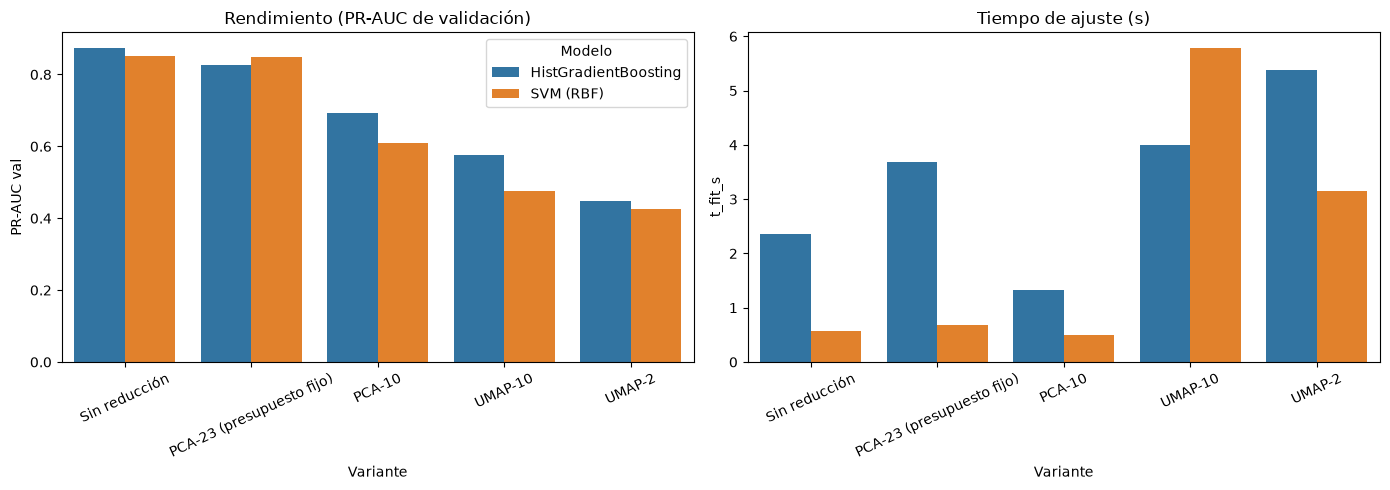

In [5]:
import sys
from pathlib import Path

raiz = Path.cwd().resolve()
candidatas_raiz = [raiz, *raiz.parents]

# En Colab el repositorio puede estar en /content/<nombre-repo>, no en el CWD.
for base in (Path("/content"), Path("/workspace"), Path("/mnt/data")):
    if base.is_dir():
        candidatas_raiz.extend(hijo for hijo in base.iterdir() if hijo.is_dir())

for candidato in candidatas_raiz:
    if (candidato / "src").is_dir() and (candidato / "notebooks").is_dir():
        sys.path.insert(0, str(candidato))
        break

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
import time

from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import MissingIndicator
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.base import clone
from sklearn.model_selection import cross_validate, cross_val_predict
from sklearn.metrics import (
    average_precision_score,
    fbeta_score,
    precision_score,
    recall_score,
    confusion_matrix,
)
from scipy import stats

from src.comun import (
    SEED,
    BETA_UMBRAL,
    COSTO_FN,
    COSTO_FP,
    guardar,
    exportar,
    cargar_estado,
    configurar_columnas,
    construir_preprocesador,
    GroupMedianImputer,
    UMAPTransformer,
    umbral_fbeta,
    costo_esperado,
    umbral_costo,
)

globals().update(cargar_estado("1_eda"))
globals().update(cargar_estado("2_preprocessing"))
globals().update(cargar_estado("3_trainig"))
globals().update(cargar_estado("4_evaluation"))
configurar_columnas(all_num_features, all_cat_features, cols_na)

top2 = tabla_cv.index[:2].tolist()
dims_orig = X_train_prep.shape[1]

def con_reductor(modelo, reductor):
    pasos = [(n, clone(s)) for n, s in modelo.steps]
    return Pipeline(pasos[:-1] + [("red", reductor)] + pasos[-1:])

variantes = {
    "Sin reducción": (None, dims_orig),
    "PCA-23 (presupuesto fijo)": (PCA(n_components=23, random_state=SEED), 23),
    "PCA-10": (PCA(n_components=10, random_state=SEED), 10),
    "UMAP-10": (UMAPTransformer(n_components=10, n_neighbors=15, min_dist=0.1, n_epochs=200, random_state=SEED, n_jobs=1), 10),
    "UMAP-2": (UMAPTransformer(n_components=2, n_neighbors=15, min_dist=0.1, n_epochs=200, random_state=SEED, n_jobs=1), 2),
}

def scores_test(modelo):
    if hasattr(modelo, "predict_proba"):
        return modelo.predict_proba(X_test)[:, 1]
    return modelo.decision_function(X_test)

filas = []
for nombre in top2:
    for v, (red, k) in variantes.items():
        pipe = clone(modelos_finales[nombre]) if red is None else con_reductor(modelos_finales[nombre], clone(red))
        r = cross_validate(pipe, X_train, y_train, cv=cv_tuning, return_train_score=True, n_jobs=-1,
                           scoring={"pr_auc": "average_precision", "roc_auc": "roc_auc"})
        t0 = time.time(); pipe.fit(X_train, y_train); t_fit = time.time() - t0
        p = scores_test(pipe)
        filas.append({"Modelo": nombre, "Variante": v, "Dimensiones": k,
                      "% reducción": 100 * (1 - k / dims_orig),
                      "PR-AUC train": r["train_pr_auc"].mean(), "PR-AUC val": r["test_pr_auc"].mean(),
                      "PR-AUC val std": r["test_pr_auc"].std(), "Brecha": r["train_pr_auc"].mean() - r["test_pr_auc"].mean(),
                      "ROC-AUC val": r["test_roc_auc"].mean(), "PR-AUC test": average_precision_score(y_test, p),
                      "t_fit_s": t_fit})
df_red = pd.DataFrame(filas)
display(df_red.round(4)); exportar(df_red.set_index("Modelo"), "12_reduccion_top2")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=df_red, x="Variante", y="PR-AUC val", hue="Modelo", ax=axes[0]); axes[0].tick_params(axis="x", rotation=25)
sns.barplot(data=df_red, x="Variante", y="t_fit_s", hue="Modelo", ax=axes[1], legend=False); axes[1].tick_params(axis="x", rotation=25)
axes[0].set_title("Rendimiento (PR-AUC de validación)"); axes[1].set_title("Tiempo de ajuste (s)")
plt.tight_layout(); guardar(fig, "12_reduccion_top2"); plt.show()

### Efecto de la reducción de dimensionalidad (HGB y SVM)

En este experimento PCA y UMAP se ajustan dentro del pipeline, en cada pliegue de la validación cruzada, y los modelos usan los hiperparámetros que ya habíamos elegido en el espacio original. La tabla anterior muestra las dimensiones, el porcentaje de reducción, el PR-AUC de validación y de test, la brecha y el ROC-AUC. Una aclaración para evitar confusiones con el notebook 2: allí PCA(0,95) retuvo 19 componentes (95,25 % de la varianza), mientras que aquí PCA-23 es un presupuesto fijo de 23 componentes, no el número que alcanza el 95 %.

En el HGB la reducción empeora el PR-AUC en todas las variantes: en validación pasa de 0,874 sin reducción a 0,827 con PCA-23, y las demás caen mucho más. En la SVM, PCA-23 mantiene la validación (0,849 contra 0,851) y sube un poco en test (de 0,924 a 0,934), pero no lo consideramos una mejora concluyente, porque la validación no mejora y el test es una sola muestra. UMAP no aporta en ningún caso y el desempeño cae de forma marcada. Por lo tanto, no adoptamos ninguna reducción: el modelo final es la SVM en el espacio original de 37 columnas procesadas, y el HGB original queda como alternativa.

In [6]:
from sklearn.metrics import accuracy_score
k = N_SPLITS * N_REPEATS

def ic_cv_nb(v):                                  # IC95 con varianza corregida (Nadeau-Bengio)
    se = np.sqrt((1 / k + 1 / (N_SPLITS - 1)) * np.var(v, ddof=1))
    h = stats.t.ppf(.975, k - 1) * se
    return v.mean() - h, v.mean() + h

filas = {}
for m in tabla_cv.index:
    lo, hi = ic_cv_nb(pr[m].to_numpy())
    yhat = (p_test[m] >= umbrales[m]).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, yhat).ravel()
    filas[m] = {"PR-AUC train": average_precision_score(y_train, modelos_test[m].predict_proba(X_train)[:, 1]),
                "PR-AUC val (CV)": pr[m].mean(), "IC95 val inf": lo, "IC95 val sup": hi,
                "PR-AUC test": tabla_test.loc[m, "PR-AUC"],
                "Exactitud test": accuracy_score(y_test, yhat), "Sensibilidad test": tp / (tp + fn),
                "Especificidad test": tn / (tn + fp)}

tabla_unificada = pd.DataFrame(filas).T

display(tabla_unificada.round(4)); exportar(tabla_unificada.round(4), "13_tabla_unificada_train_val_test")

,PR-AUC train,PR-AUC val (CV),IC95 val inf,IC95 val sup,PR-AUC test,Exactitud test,Sensibilidad test,Especificidad test
HistGradientBoosting,1.0000,0.8784,0.8484,0.9085,0.9228,0.9202,0.9345,0.9174
SVM (RBF),1.0000,0.8580,0.8232,0.8927,0.9243,0.9586,0.8571,0.9787
Random Forest,1.0000,0.8462,0.8141,0.8784,0.9124,0.9360,0.8869,0.9457
MLP,0.9974,0.7997,0.7560,0.8434,0.8614,0.9005,0.8333,0.9138
KNN,1.0000,0.7806,0.7424,0.8188,0.8730,0.8946,0.9167,0.8902
Regresión Logística,0.7096,0.6977,0.6565,0.7388,0.7213,0.7823,0.8214,0.7745


La tabla reúne la validación y el test de los seis modelos. El HGB y la SVM mantienen un rendimiento parecido en ambas: el HGB con 0,878 en CV y 0,923 en test, y la SVM con 0,858 y 0,924. En el test la SVM tiene la mayor exactitud (0,959) y la mayor especificidad (0,979), mientras que el HGB conserva la mayor sensibilidad (0,93). Esto no cambia la decisión: la SVM sigue siendo el modelo final por costo y el HGB la alternativa si se prioriza el recall.

### Auditoría de la política grupo (OOF vs test)

,particion,filas,grupos,singletons,pares,filas_en_pares,peso_total,peso_min,peso_max,churn_singletons,churn_pares
0,train,4058,3113,2168,945,1890,3113.0,1.0,1.0,0.1388,0.1968
1,test,1015,778,541,237,474,778.0,1.0,1.0,0.1368,0.1983


,Modelo,Conjunto,Umbral,PR-AUC cliente,PR-AUC grupo,F2 cliente,F2 grupo
0,HistGradientBoosting,OOF,0.0097,0.8717,0.8837,0.8219,0.8357
1,HistGradientBoosting,test,0.0097,0.9228,0.9266,0.8732,0.8783
2,SVM (RBF),OOF,0.2101,0.8431,0.8485,0.8379,0.8441
3,SVM (RBF),test,0.2101,0.9243,0.9297,0.8633,0.8667
4,Random Forest,OOF,0.2200,0.8344,0.8451,0.8237,0.8308
5,Random Forest,test,0.2200,0.9124,0.9056,0.8593,0.8604


Chequeo de alineación tabla_test vs auditoría: OK


,Modelo,Conjunto,Métrica,Estimación,IC95 inf,IC95 sup
0,HistGradientBoosting,OOF,PR-AUC cliente,0.8717,0.8445,0.8962
1,HistGradientBoosting,OOF,PR-AUC grupo,0.8837,0.8588,0.9061
2,HistGradientBoosting,OOF,F2 cliente,0.8219,0.7956,0.8478
3,HistGradientBoosting,OOF,F2 grupo,0.8357,0.8114,0.8581
4,HistGradientBoosting,test,PR-AUC cliente,0.9228,0.8823,0.9567
5,HistGradientBoosting,test,PR-AUC grupo,0.9266,0.8900,0.9564
6,HistGradientBoosting,test,F2 cliente,0.8732,0.8221,0.9116
7,HistGradientBoosting,test,F2 grupo,0.8783,0.8353,0.9134
8,SVM (RBF),OOF,PR-AUC cliente,0.8431,0.8038,0.8801
9,SVM (RBF),OOF,PR-AUC grupo,0.8485,0.8139,0.8818


,Modelo,Conjunto,Tamaño de grupo,n filas,PR-AUC,F2
0,HistGradientBoosting,OOF,1,2168,0.9096,0.8665
1,HistGradientBoosting,OOF,2,1890,0.8391,0.7857
2,HistGradientBoosting,test,1,541,0.9371,0.8897
3,HistGradientBoosting,test,2,474,0.9161,0.8600
4,SVM (RBF),OOF,1,2168,0.8641,0.8579
5,SVM (RBF),OOF,2,1890,0.8332,0.8216
6,SVM (RBF),test,1,541,0.9426,0.8743
7,SVM (RBF),test,2,474,0.9117,0.8547
8,Random Forest,OOF,1,2168,0.8689,0.8466
9,Random Forest,OOF,2,1890,0.8061,0.8047


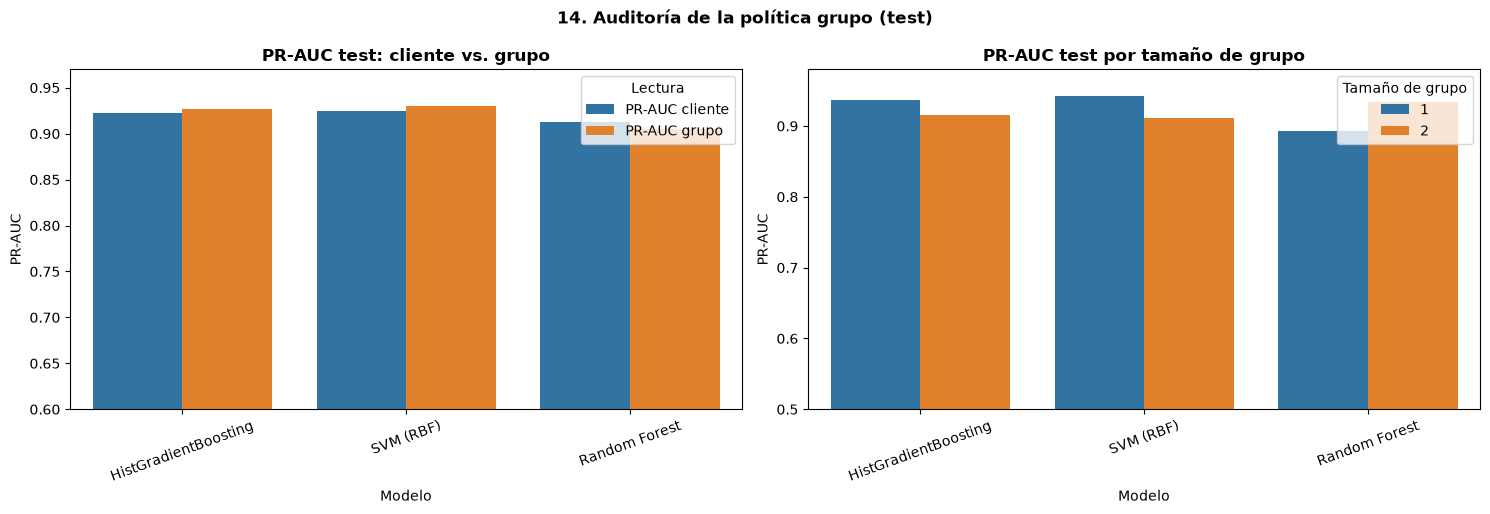

In [8]:
def resumen_pesos(nombre, groups, weights, target):
    dfw = pd.DataFrame({"grupo": groups, "peso": weights, "churn": np.asarray(target)})
    g = dfw.groupby("grupo").agg(n=("peso", "size"), peso_total=("peso", "sum"), churn=("churn", "mean"))
    return {
        "particion": nombre,
        "filas": len(dfw),
        "grupos": int(g.shape[0]),
        "singletons": int((g["n"] == 1).sum()),
        "pares": int((g["n"] == 2).sum()),
        "filas_en_pares": int(g.loc[g["n"] > 1, "n"].sum()),
        "peso_total": float(g["peso_total"].sum()),
        "peso_min": float(g["peso_total"].min()),
        "peso_max": float(g["peso_total"].max()),
        "churn_singletons": float(g.loc[g["n"] == 1, "churn"].mean()),
        "churn_pares": float(g.loc[g["n"] == 2, "churn"].mean()),
    }

auditoria_pesos = pd.DataFrame([
    resumen_pesos("train", grupos_train, w_train, y_train),
    resumen_pesos("test", grupos_test, w_test, y_test),
])
display(auditoria_pesos.round(4))
exportar(auditoria_pesos.round(4), "14_auditoria_pesos_grupo")

MODELOS_AUDITORIA = ["HistGradientBoosting", "SVM (RBF)", "Random Forest"]

def metricas_politica(y, p, thr, weights):
    yhat = (np.asarray(p) >= thr).astype(int)
    return {
        "PR-AUC cliente": average_precision_score(y, p),
        "PR-AUC grupo": average_precision_score(y, p, sample_weight=weights),
        "F2 cliente": fbeta_score(y, yhat, beta=BETA_UMBRAL, zero_division=0),
        "F2 grupo": fbeta_score(y, yhat, beta=BETA_UMBRAL, sample_weight=weights, zero_division=0),
    }

filas_metricas = []
for m in MODELOS_AUDITORIA:
    for conjunto, y_, p_, g_, w_, thr in [
        ("OOF", y_train, oof[m], grupos_train, w_train, umbrales[m]),
        ("test", y_test, p_test[m], grupos_test, w_test, umbrales[m]),
    ]:
        met = metricas_politica(y_, p_, thr, w_)
        filas_metricas.append({"Modelo": m, "Conjunto": conjunto, "Umbral": thr, **met})

auditoria_metricas = pd.DataFrame(filas_metricas)
display(auditoria_metricas.round(4))
exportar(auditoria_metricas.round(4), "14_auditoria_metricas_politica")

for m in MODELOS_AUDITORIA:
    valor_tabla = float(tabla_test.loc[m, "PR-AUC ponderado (grupos)"])
    valor_audit = float(
        auditoria_metricas.query("Modelo == @m and Conjunto == 'test'")["PR-AUC grupo"].iloc[0]
    )
    assert np.isclose(valor_tabla, valor_audit, atol=1e-9), (
        f"Desalineación en {m}: tabla_test={valor_tabla:.6f}, auditoría={valor_audit:.6f}"
    )
print("Chequeo de alineación tabla_test vs auditoría: OK")

def bootstrap_politica(y, p, groups, weights, thr, n_boot=N_BOOT, seed=SEED):
    rng = np.random.default_rng(seed)
    ug = np.unique(groups)
    pos = {g: np.flatnonzero(groups == g) for g in ug}
    y = np.asarray(y)
    p = np.asarray(p)
    weights = np.asarray(weights)
    filas = []
    for _ in range(n_boot):
        idx = np.concatenate([pos[g] for g in rng.choice(ug, size=len(ug), replace=True)])
        if y[idx].min() == y[idx].max():
            continue
        yhat = (p[idx] >= thr).astype(int)
        filas.append({
            "PR-AUC cliente": average_precision_score(y[idx], p[idx]),
            "PR-AUC grupo": average_precision_score(y[idx], p[idx], sample_weight=weights[idx]),
            "F2 cliente": fbeta_score(y[idx], yhat, beta=BETA_UMBRAL, zero_division=0),
            "F2 grupo": fbeta_score(y[idx], yhat, beta=BETA_UMBRAL, sample_weight=weights[idx], zero_division=0),
        })
    return pd.DataFrame(filas)

filas_ic = []
for m in MODELOS_AUDITORIA:
    for conjunto, y_, p_, g_, w_, thr in [
        ("OOF", y_train, oof[m], grupos_train, w_train, umbrales[m]),
        ("test", y_test, p_test[m], grupos_test, w_test, umbrales[m]),
    ]:
        boot = bootstrap_politica(y_, p_, g_, w_, thr)
        puntual = metricas_politica(y_, p_, thr, w_)
        for met in boot.columns:
            filas_ic.append({
                "Modelo": m,
                "Conjunto": conjunto,
                "Métrica": met,
                "Estimación": puntual[met],
                "IC95 inf": boot[met].quantile(0.025),
                "IC95 sup": boot[met].quantile(0.975),
            })

auditoria_ic = pd.DataFrame(filas_ic)
display(auditoria_ic.round(4))
exportar(auditoria_ic.round(4), "14_auditoria_ic_politica_grupo")

filas_tam = []
for m in MODELOS_AUDITORIA:
    for conjunto, y_, p_, g_, thr in [
        ("OOF", y_train, oof[m], grupos_train, umbrales[m]),
        ("test", y_test, p_test[m], grupos_test, umbrales[m]),
    ]:
        tamanos = pd.Series(g_).value_counts()
        for tam in sorted(tamanos.unique()):
            mask = np.isin(g_, tamanos[tamanos == tam].index)
            if not mask.any():
                continue
            yy = np.asarray(y_)[mask]
            pp = np.asarray(p_)[mask]
            if yy.min() == yy.max():
                continue
            yhat = (pp >= thr).astype(int)
            filas_tam.append({
                "Modelo": m,
                "Conjunto": conjunto,
                "Tamaño de grupo": int(tam),
                "n filas": int(mask.sum()),
                "PR-AUC": average_precision_score(yy, pp),
                "F2": fbeta_score(yy, yhat, beta=BETA_UMBRAL, zero_division=0),
            })

auditoria_tam = pd.DataFrame(filas_tam)
display(auditoria_tam.round(4))
exportar(auditoria_tam.round(4), "14_auditoria_por_tamano_grupo")

# 5) Figura resumen
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))

largo = auditoria_metricas.melt(
    id_vars=["Modelo", "Conjunto"],
    value_vars=["PR-AUC cliente", "PR-AUC grupo"],
    var_name="Lectura", value_name="PR-AUC",
)
largo_test = largo[largo["Conjunto"] == "test"]
sns.barplot(data=largo_test, x="Modelo", y="PR-AUC", hue="Lectura", ax=axes[0])
axes[0].set_title("PR-AUC test: cliente vs. grupo", fontweight="bold")
axes[0].tick_params(axis="x", rotation=20)
axes[0].set_ylim(0.6, 0.97)

largo_tam = auditoria_tam[auditoria_tam["Conjunto"] == "test"].copy()
largo_tam["Tamaño de grupo"] = largo_tam["Tamaño de grupo"].astype(str)
sns.barplot(data=largo_tam, x="Modelo", y="PR-AUC", hue="Tamaño de grupo", ax=axes[1])
axes[1].set_title("PR-AUC test por tamaño de grupo", fontweight="bold")
axes[1].tick_params(axis="x", rotation=20)
axes[1].set_ylim(0.5, 0.98)

fig.suptitle("14. Auditoría de la política grupo (test)", fontweight="bold")
plt.tight_layout()
guardar(fig, "14_auditoria_politica_grupo")

plt.show()

Los pesos de la auditoría están bien construidos: cada grupo pesa 1, así que el peso total coincide con el número de grupos (3.113 en train y 778 en test). La composición también es parecida entre las dos particiones: cerca del 46,6 % de las filas de train y del 46,7 % de las de test están en pares de casi duplicados, y la tasa de abandono por tipo de grupo es similar. Con la política por grupo, las métricas del HGB y de la SVM suben ligeramente respecto a las de cliente; en el Random Forest quedan cercanas (el F2 sube y el PR-AUC en test baja un poco). El chequeo de alineación dio OK, es decir, la tabla de test y la auditoría describen la misma política. En conjunto, el desempeño no depende de unos pocos grupos.

### Ablación de variables post-hoc (`Tenure` y `DaySinceLastOrder`)

c:\Users\ASUS\Desktop\V8-final\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\ASUS\Desktop\V8-final\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\ASUS\Desktop\V8-final\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\ASUS\Desktop\V8-final\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated 

,Modelo,Escenario,Variables excluidas,Dim. procesadas,PR-AUC CV,PR-AUC CV std,ROC-AUC CV,PR-AUC test,F2 test,Precisión test,Recall test,Costo OOF 5:1,Umbral OOF,Δ PR-AUC CV,Δ PR-AUC test,Δ F2 test,Δ Costo OOF
0,SVM (RBF),Completo,ninguna,37,0.8580,0.0306,0.9518,0.9243,0.8633,0.8889,0.8571,654.0,0.2100,0.0000,0.0000,0.0000,0.0
1,SVM (RBF),Sin Tenure,Tenure,35,0.7752,0.0335,0.9149,0.8912,0.8371,0.6835,0.8869,1000.0,0.1180,-0.0828,-0.0331,-0.0262,346.0
2,SVM (RBF),Sin DaySinceLastOrder,DaySinceLastOrder,35,0.8433,0.0293,0.9455,0.9143,0.8796,0.7917,0.9048,662.0,0.1710,-0.0147,-0.0101,0.0163,8.0
3,SVM (RBF),Sin ambas,"Tenure, DaySinceLastOrder",33,0.7492,0.0373,0.9052,0.8371,0.8002,0.6197,0.8631,1001.0,0.1530,-0.1088,-0.0873,-0.0631,347.0
4,HistGradientBoosting,Completo,ninguna,37,0.8784,0.0265,0.9595,0.9228,0.8732,0.6916,0.9345,723.0,0.0097,0.0000,0.0000,0.0000,0.0
5,HistGradientBoosting,Sin Tenure,Tenure,35,0.7806,0.0357,0.9155,0.8260,0.7750,0.4726,0.9226,1122.0,0.0142,-0.0978,-0.0968,-0.0982,399.0
6,HistGradientBoosting,Sin DaySinceLastOrder,DaySinceLastOrder,35,0.8774,0.0233,0.9592,0.8961,0.8706,0.7562,0.9048,749.0,0.0277,-0.0010,-0.0267,-0.0026,26.0
7,HistGradientBoosting,Sin ambas,"Tenure, DaySinceLastOrder",33,0.7707,0.0322,0.9112,0.8165,0.7778,0.4843,0.9167,1194.0,0.0191,-0.1077,-0.1063,-0.0954,471.0


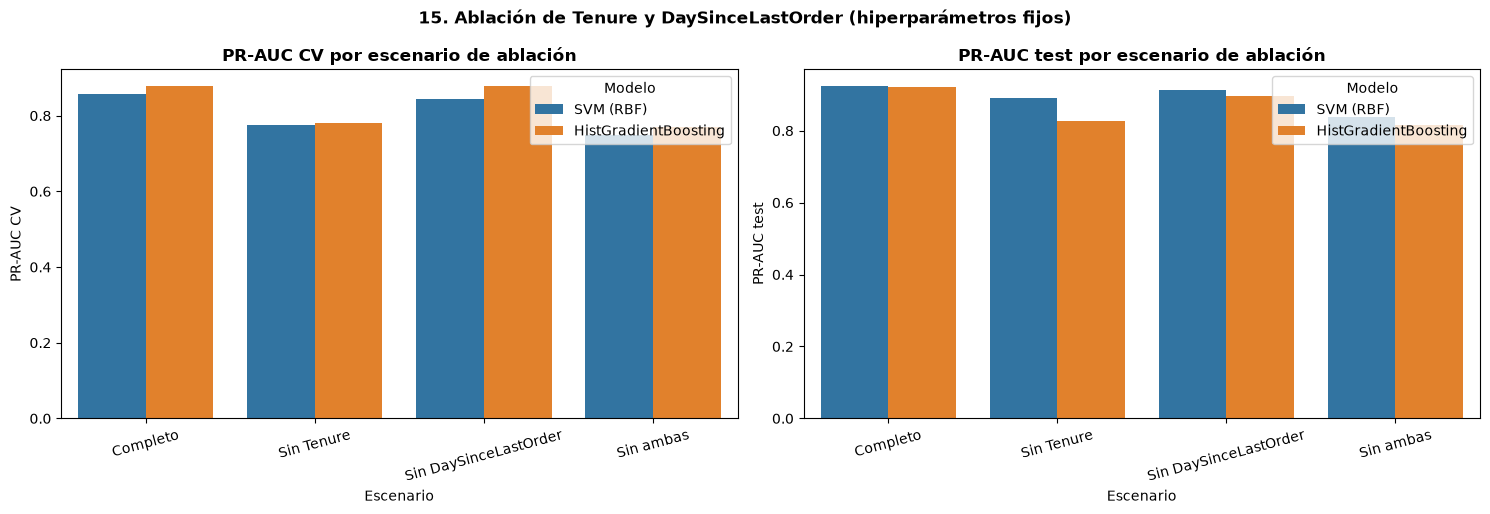

In [ ]:
def construir_preprocesador_ablacion(num_features):
    grupo = "PreferedOrderCat"
    num_features = list(num_features)
    cols_na_abl = [c for c in cols_na if c in num_features]
    group_num_pipe = Pipeline([
        ("group_imp", GroupMedianImputer(group_col=grupo, num_cols=num_features)),
        ("scaler", StandardScaler()),
    ])
    return ColumnTransformer([
        ("num_group", group_num_pipe, num_features + [grupo]),
        ("na_ind", MissingIndicator(features="missing-only"), cols_na_abl),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), all_cat_features),
    ])

ESCENARIOS_ABL = {
    "Completo": [],
    "Sin Tenure": ["Tenure"],
    "Sin DaySinceLastOrder": ["DaySinceLastOrder"],
    "Sin ambas": ["Tenure", "DaySinceLastOrder"],
}

CLF_ABL = {
    "SVM (RBF)": SVC(
        kernel="rbf", C=100, gamma=0.1, class_weight="balanced",
        probability=True, cache_size=500, random_state=SEED,
    ),
    "HistGradientBoosting": HistGradientBoostingClassifier(
        max_iter=300, learning_rate=0.05, max_leaf_nodes=63,
        min_samples_leaf=5, l2_regularization=0.0, random_state=SEED,
    ),
}

filas_abl = []
for modelo, clf in CLF_ABL.items():
    for escenario, excluidas in ESCENARIOS_ABL.items():
        Xtr = X_train.drop(columns=excluidas)
        Xte = X_test.drop(columns=excluidas)
        num_features = [c for c in all_num_features if c not in excluidas]
        pipe = Pipeline([
            ("prep", construir_preprocesador_ablacion(num_features)),
            ("clf", clone(clf)),
        ])
        r = cross_validate(
            pipe, Xtr, y_train, cv=cv_rep,
            scoring={"pr_auc": "average_precision", "roc_auc": "roc_auc"},
            n_jobs=-1,
        )
        oof_abl = cross_val_predict(
            clone(pipe), Xtr, y_train, cv=cv_tuning,
            method="predict_proba", n_jobs=-1,
        )[:, 1]
        if modelo == "SVM (RBF)":
            thr = umbral_costo(y_train, oof_abl)
        else:
            thr = umbral_fbeta(y_train, oof_abl)[0]
        costo = costo_esperado(y_train, (oof_abl >= thr).astype(int))
        pipe.fit(Xtr, y_train)
        p_te = pipe.predict_proba(Xte)[:, 1]
        yhat = (p_te >= thr).astype(int)
        dims = pipe.named_steps["prep"].transform(Xtr).shape[1]
        filas_abl.append({
            "Modelo": modelo,
            "Escenario": escenario,
            "Variables excluidas": ", ".join(excluidas) if excluidas else "ninguna",
            "Dim. procesadas": dims,
            "PR-AUC CV": r["test_pr_auc"].mean(),
            "PR-AUC CV std": r["test_pr_auc"].std(),
            "ROC-AUC CV": r["test_roc_auc"].mean(),
            "PR-AUC test": average_precision_score(y_test, p_te),
            "F2 test": fbeta_score(y_test, yhat, beta=BETA_UMBRAL, zero_division=0),
            "Precisión test": precision_score(y_test, yhat, zero_division=0),
            "Recall test": recall_score(y_test, yhat),
            "Costo OOF 5:1": costo,
            "Umbral OOF": thr,
        })

tabla_abl = pd.DataFrame(filas_abl)
for m in tabla_abl["Modelo"].unique():
    base = tabla_abl[(tabla_abl["Modelo"] == m) & (tabla_abl["Escenario"] == "Completo")].iloc[0]
    mask = tabla_abl["Modelo"] == m
    tabla_abl.loc[mask, "Δ PR-AUC CV"] = tabla_abl.loc[mask, "PR-AUC CV"] - base["PR-AUC CV"]
    tabla_abl.loc[mask, "Δ PR-AUC test"] = tabla_abl.loc[mask, "PR-AUC test"] - base["PR-AUC test"]
    tabla_abl.loc[mask, "Δ F2 test"] = tabla_abl.loc[mask, "F2 test"] - base["F2 test"]
    tabla_abl.loc[mask, "Δ Costo OOF"] = tabla_abl.loc[mask, "Costo OOF 5:1"] - base["Costo OOF 5:1"]

display(tabla_abl.round(4))
exportar(tabla_abl.round(4), "15_ablacion_tenure_days")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
sns.barplot(data=tabla_abl, x="Escenario", y="PR-AUC CV", hue="Modelo", ax=axes[0])
axes[0].set_title("PR-AUC CV por escenario de ablación", fontweight="bold")
axes[0].tick_params(axis="x", rotation=15)
sns.barplot(data=tabla_abl, x="Escenario", y="PR-AUC test", hue="Modelo", ax=axes[1])
axes[1].set_title("PR-AUC test por escenario de ablación", fontweight="bold")
axes[1].tick_params(axis="x", rotation=15)
fig.suptitle("15. Ablación de Tenure y DaySinceLastOrder (hiperparámetros fijos)", fontweight="bold")

plt.tight_layout()

guardar(fig, "15_ablacion_tenure_days")

plt.show()

Quitar Tenure es lo que más daña a los dos modelos. En la SVM, la CV baja de 0,858 a 0,775, el test de 0,924 a 0,891 y el costo OOF sube de 654 a 1.000; en el HGB, la CV cae a 0,781 y el test a 0,826. DaySinceLastOrder pesa mucho menos: en la CV cambia poco (0,843 en la SVM y 0,877 en el HGB), aunque en test sí se nota algo, con la SVM en 0,914 y el HGB en 0,896. Por eso mantenemos Tenure en el modelo final, pero declaramos la dependencia como un riesgo post-hoc, porque puede ser una variable que no esté disponible antes de que el cliente abandone.

## Cierre del análisis

De todo esto notamos que ni PCA ni UMAP mejoran la validación cruzada, así que no los adoptamos; la única mejora que vimos fue la de la SVM con PCA-23 en test, y no es concluyente. La auditoría por grupos es consistente con lo que veníamos viendo, y la ablación muestra que Tenure es la variable de la que más depende el modelo, mientras que DaySinceLastOrder aporta bastante menos. Retirar Tenure degrada el desempeño, por lo que la dependencia queda declarada como riesgo post-hoc. El pipeline final se mantiene sin reducción, con la SVM como modelo elegido por costo y el HGB como alternativa de mayor recall.